# Week 6 - Day 1

# Perceptron & Artificial Neural Networks (ANN)

In Week 5, we built models that draw a boundary (Logistic Regression) and models that ask a series of yes/no questions (Decision Trees).

Today we start a new family of models: **Neural Networks**.

Neural Networks are the foundation of modern Deep Learning - the technology behind ChatGPT, facial recognition, self-driving cars, and voice assistants like Siri and Google Assistant.

We will build our understanding from the smallest possible unit - a single **neuron** - all the way up to a working **Artificial Neural Network (ANN)** trained on a real (and realistically messy) loan approval dataset.

## Learning Objectives

By the end of this lesson, you will be able to:

- Explain the biological inspiration behind neural networks.
- Describe how an artificial neuron (a Perceptron) works.
- Explain weights, bias, and activation functions.
- Compare the Step, Sigmoid, and ReLU activation functions.
- Identify the main types of neural networks (ANN, CNN, RNN) and what each is used for.
- Install and verify TensorFlow/Keras.
- Implement a Perceptron from scratch using NumPy.
- Clean a large, messy, real-world-style dataset before modelling.
- Encode categorical features and scale numerical features for a Neural Network.
- Build, compile, and train a Keras `Sequential` ANN.
- Evaluate an ANN using accuracy, a confusion matrix, and a classification report.
- Visualize training loss and accuracy across epochs.
- Explain why Neural Networks need feature scaling, unlike Decision Trees.

## Why This Lesson Matters

Imagine a bank loan officer at a busy branch in Lagos.

Every day, hundreds of applications arrive: some applicants are salaried workers, some are self-employed, some have a co-applicant, some have a poor credit history.

A Decision Tree asks a fixed sequence of questions. A Neural Network instead behaves more like **thousands of tiny decision-makers (neurons) working together**, each paying attention to a different combination of signals, and combining their opinions into one final decision.

This is the same underlying idea used by much bigger systems - it just starts here, with a single neuron.

## Recap: Where We've Been

| Week | Model | What it Does |
|---|---|---|
| Week 4 | Linear Regression | Predicts a continuous number |
| Week 4 | K-Means | Finds groups with no labels |
| Week 5 | Logistic Regression | Draws a mathematical boundary between classes |
| Week 5 | Decision Tree | Splits data using a series of learned questions |
| **Week 6** | **Neural Network (ANN)** | **Combines many small "neurons" to learn complex patterns** |

Neural Networks can do everything the earlier models could do, and more - but they usually need more data, more computation, and more careful data preparation. Today's dataset (~1,000 rows) is deliberately larger than our earlier lessons for this reason.

# Part 1 - From Biological Neuron to Artificial Neuron

### The Human Brain's Neuron

Your brain contains roughly 86 billion **neurons**. Each one is a tiny cell that:

1. Receives electrical signals through branches called **dendrites**.
2. Combines those signals inside the **cell body**.
3. If the combined signal is strong enough, it "fires" a signal down the **axon**.
4. That signal passes to the next neuron through a connection point called a **synapse**.

Artificial Neural Networks are a deliberately simplified, mathematical copy of this idea.

### Biological Neuron

<svg viewBox="0 0 900 380" xmlns="http://www.w3.org/2000/svg">
  <rect width="900" height="380" fill="#f8f9fa"/>

  <ellipse cx="200" cy="190" rx="90" ry="70" fill="#fce4ec" stroke="#c2185b" stroke-width="3"/>
  <text x="200" y="185" font-size="16" font-weight="bold" text-anchor="middle" fill="#880e4f">Cell Body</text>
  <text x="200" y="205" font-size="12" text-anchor="middle" fill="#424242">(combines signals)</text>

  <line x1="140" y1="140" x2="60" y2="80" stroke="#c2185b" stroke-width="2"/>
  <line x1="130" y1="160" x2="40" y2="140" stroke="#c2185b" stroke-width="2"/>
  <line x1="130" y1="220" x2="40" y2="240" stroke="#c2185b" stroke-width="2"/>
  <line x1="140" y1="240" x2="60" y2="300" stroke="#c2185b" stroke-width="2"/>
  <text x="90" y="180" font-size="13" font-weight="bold" fill="#424242">Dendrites</text>
  <text x="90" y="196" font-size="11" fill="#666">(inputs)</text>

  <line x1="290" y1="190" x2="620" y2="190" stroke="#1976d2" stroke-width="6"/>
  <text x="450" y="175" font-size="16" font-weight="bold" text-anchor="middle" fill="#0d47a1">Axon</text>
  <text x="450" y="215" font-size="12" text-anchor="middle" fill="#424242">(carries the output signal)</text>

  <circle cx="650" cy="190" r="18" fill="#fff3e0" stroke="#f57c00" stroke-width="3"/>
  <text x="650" y="240" font-size="14" font-weight="bold" text-anchor="middle" fill="#e65100">Synapse</text>
  <text x="650" y="256" font-size="11" text-anchor="middle" fill="#666">(connects to next neuron)</text>

  <line x1="668" y1="190" x2="780" y2="190" stroke="#9e9e9e" stroke-width="2" stroke-dasharray="6,4"/>
  <text x="800" y="195" font-size="13" fill="#666">Next neuron →</text>

  <text x="450" y="340" font-size="13" text-anchor="middle" fill="#555">Inputs arrive → combined in the cell body → if strong enough, a signal fires down the axon → passed to the next neuron</text>
</svg>

### Mapping Biology to Mathematics

| Biological Neuron | Artificial Neuron |
|---|---|
| Dendrites (receive signals) | Inputs (`x1, x2, x3, ...`) |
| Signal strength at each dendrite | Weights (`w1, w2, w3, ...`) |
| Cell body (combines signals) | Weighted sum + bias |
| "Fires" if signal is strong enough | Activation function |
| Axon (sends the output) | Output (`y`) |

An artificial neuron doesn't simulate biology exactly - it borrows the *idea* of "combine inputs, then decide whether to fire" and turns it into simple arithmetic.

<svg viewBox="0 0 900 400" xmlns="http://www.w3.org/2000/svg">
  <rect width="900" height="400" fill="#f8f9fa"/>

  <circle cx="80" cy="90" r="10" fill="#1976d2"/>
  <text x="30" y="95" font-size="14" fill="#333">x1</text>
  <circle cx="80" cy="190" r="10" fill="#1976d2"/>
  <text x="30" y="195" font-size="14" fill="#333">x2</text>
  <circle cx="80" cy="290" r="10" fill="#1976d2"/>
  <text x="30" y="295" font-size="14" fill="#333">x3</text>

  <line x1="90" y1="90" x2="360" y2="180" stroke="#90a4ae" stroke-width="2"/>
  <text x="200" y="120" font-size="12" fill="#455a64">w1</text>
  <line x1="90" y1="190" x2="360" y2="195" stroke="#90a4ae" stroke-width="2"/>
  <text x="200" y="185" font-size="12" fill="#455a64">w2</text>
  <line x1="90" y1="290" x2="360" y2="210" stroke="#90a4ae" stroke-width="2"/>
  <text x="200" y="270" font-size="12" fill="#455a64">w3</text>

  <circle cx="400" cy="195" r="55" fill="#e3f2fd" stroke="#1565c0" stroke-width="3"/>
  <text x="400" y="180" font-size="13" font-weight="bold" text-anchor="middle" fill="#0d47a1">Weighted Sum</text>
  <text x="400" y="200" font-size="12" text-anchor="middle" fill="#333">(w1x1+w2x2+w3x3)</text>
  <text x="400" y="218" font-size="12" text-anchor="middle" fill="#333">+ bias (b)</text>

  <line x1="455" y1="195" x2="600" y2="195" stroke="#455a64" stroke-width="2"/>

  <rect x="600" y="140" width="150" height="110" rx="12" fill="#fff3e0" stroke="#f57c00" stroke-width="3"/>
  <text x="675" y="185" font-size="14" font-weight="bold" text-anchor="middle" fill="#e65100">Activation</text>
  <text x="675" y="205" font-size="14" font-weight="bold" text-anchor="middle" fill="#e65100">Function</text>
  <text x="675" y="228" font-size="11" text-anchor="middle" fill="#666">(decides if it "fires")</text>

  <line x1="750" y1="195" x2="830" y2="195" stroke="#455a64" stroke-width="3"/>
  <circle cx="850" cy="195" r="12" fill="#2e7d32"/>
  <text x="830" y="230" font-size="14" font-weight="bold" text-anchor="middle" fill="#2e7d32">y</text>

  <text x="450" y="350" font-size="13" text-anchor="middle" fill="#555">Each input is multiplied by a learned weight, summed together with a bias, then passed through an activation function to produce the output.</text>
</svg>

### Key Takeaways from Part 1

1. A biological neuron receives, combines, and (maybe) fires a signal.
2. An artificial neuron copies this: **inputs → weighted sum + bias → activation → output**.
3. Weights are learned automatically from data. Nobody hand-writes them.

# Part 2 - The Perceptron

**The Perceptron is the simplest possible artificial neuron, and the earliest neural network model (1958).**

Given inputs `x1, x2, ..., xn`, weights `w1, w2, ..., wn`, and a bias `b`, the Perceptron computes:

```
z = (w1*x1) + (w2*x2) + ... + (wn*xn) + b
```

Then it applies a **Step Function**:

```
output = 1  if z >= 0
output = 0  if z < 0
```

That's it. The entire model is: multiply, add, then compare to a threshold.

### Where Do the Weights Come From?

At first, weights are random. During training, the Perceptron:

1. Makes a prediction.
2. Compares it to the correct answer.
3. Slightly adjusts each weight to reduce the error.
4. Repeats this thousands of times.

This adjustment process is the seed of what today's giant Deep Learning models still do - just at a vastly larger scale.

### Limitation of a Single Perceptron

A single Perceptron can only separate data with a **straight line** (or a flat plane in higher dimensions). Famously, a single Perceptron **cannot learn the XOR problem** (inputs that alternate: 0,1 → 1 and 0,0 → 0).

This limitation is exactly why we stack neurons into **layers** - which is what turns a Perceptron into a full Artificial Neural Network (ANN).

# Part 3 - Activation Functions

An activation function decides how strongly a neuron "fires." Without one, stacking layers would be mathematically pointless (multiple linear layers collapse into a single linear layer).

Let's look at the three most common activation functions and actually plot them.

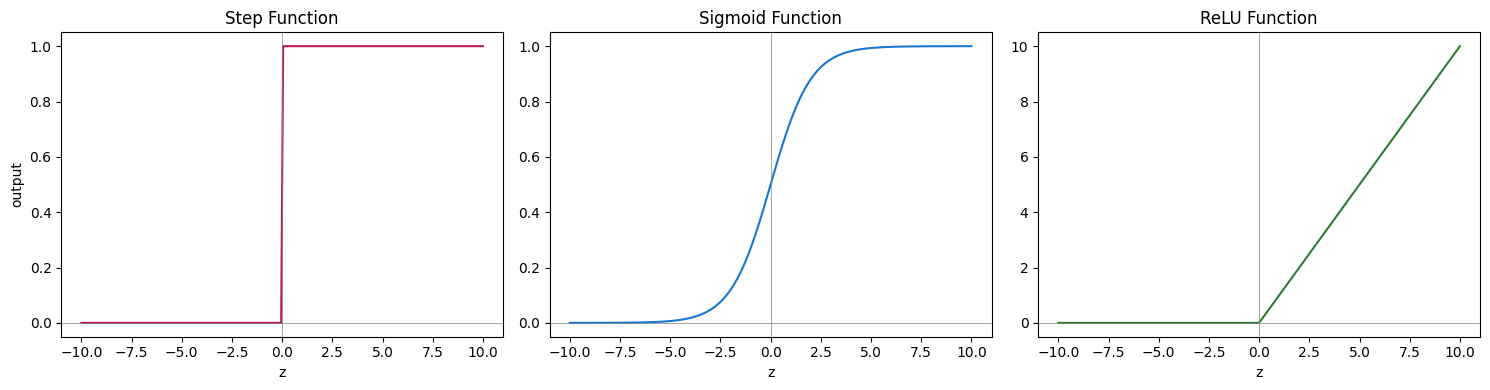

In [1]:
import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(-10, 10, 200)

def step_function(z):
    return np.where(z >= 0, 1, 0)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(z, step_function(z), color="#c2185b")
axes[0].set_title("Step Function")
axes[0].set_xlabel("z")
axes[0].set_ylabel("output")

axes[1].plot(z, sigmoid(z), color="#1976d2")
axes[1].set_title("Sigmoid Function")
axes[1].set_xlabel("z")

axes[2].plot(z, relu(z), color="#2e7d32")
axes[2].set_title("ReLU Function")
axes[2].set_xlabel("z")

for ax in axes:
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.axvline(0, color="grey", linewidth=0.5)

plt.tight_layout()
plt.show()

### Reading the Three Functions

| Function | Output Range | Used When |
|---|---|---|
| **Step** | Exactly `0` or `1` | The original Perceptron (rarely used today) |
| **Sigmoid** | Smooth curve between `0` and `1` | Output layer of binary classification models |
| **ReLU** | `0` for negative input, otherwise the input itself | Hidden layers of almost all modern Neural Networks |

**Why ReLU for hidden layers?** It is simple, fast to compute, and helps deep networks avoid a problem called the *vanishing gradient*, where earlier layers stop learning. We will use ReLU in our hidden layers and Sigmoid in our output layer, since we are doing binary classification (`Loan_Approved` = 0 or 1).

# Part 4 - Types of Deep Learning Networks

A single neuron is just the building block. Depending on how neurons are arranged, we get different network *architectures*, each suited to a different kind of data.

<svg viewBox="0 0 900 520" xmlns="http://www.w3.org/2000/svg">
  <rect width="900" height="520" fill="#f8f9fa"/>
  <text x="450" y="40" font-size="20" font-weight="bold" text-anchor="middle" fill="#1565c0">Deep Learning: Common Network Architectures</text>

  <rect x="40" y="80" width="250" height="180" rx="14" fill="#e3f2fd" stroke="#1565c0" stroke-width="3"/>
  <text x="165" y="115" font-size="16" font-weight="bold" text-anchor="middle" fill="#0d47a1">ANN</text>
  <text x="165" y="135" font-size="11" text-anchor="middle" fill="#424242">Artificial Neural Network</text>
  <text x="165" y="165" font-size="11" text-anchor="middle" fill="#333">Fully-connected layers</text>
  <text x="165" y="183" font-size="11" text-anchor="middle" fill="#333">Best for: tabular data</text>
  <text x="165" y="201" font-size="11" text-anchor="middle" fill="#333">(spreadsheets, forms,</text>
  <text x="165" y="219" font-size="11" text-anchor="middle" fill="#333">loan/customer records)</text>
  <text x="165" y="245" font-size="11" font-weight="bold" text-anchor="middle" fill="#1565c0">← Today's lesson</text>

  <rect x="325" y="80" width="250" height="180" rx="14" fill="#fff3e0" stroke="#f57c00" stroke-width="3"/>
  <text x="450" y="115" font-size="16" font-weight="bold" text-anchor="middle" fill="#e65100">CNN</text>
  <text x="450" y="135" font-size="11" text-anchor="middle" fill="#424242">Convolutional Neural Network</text>
  <text x="450" y="165" font-size="11" text-anchor="middle" fill="#333">Scans images with filters</text>
  <text x="450" y="183" font-size="11" text-anchor="middle" fill="#333">Best for: images, video</text>
  <text x="450" y="201" font-size="11" text-anchor="middle" fill="#333">(object detection,</text>
  <text x="450" y="219" font-size="11" text-anchor="middle" fill="#333">facial recognition)</text>
  <text x="450" y="245" font-size="11" text-anchor="middle" fill="#e65100">Coming in Week 7</text>

  <rect x="610" y="80" width="250" height="180" rx="14" fill="#f3e5f5" stroke="#7b1fa2" stroke-width="3"/>
  <text x="735" y="115" font-size="16" font-weight="bold" text-anchor="middle" fill="#6a1b9a">RNN / Transformer</text>
  <text x="735" y="135" font-size="11" text-anchor="middle" fill="#424242">Sequence models</text>
  <text x="735" y="165" font-size="11" text-anchor="middle" fill="#333">Remembers order/context</text>
  <text x="735" y="183" font-size="11" text-anchor="middle" fill="#333">Best for: text, speech,</text>
  <text x="735" y="201" font-size="11" text-anchor="middle" fill="#333">time series</text>
  <text x="735" y="219" font-size="11" text-anchor="middle" fill="#333">(ChatGPT, translation)</text>
  <text x="735" y="245" font-size="11" text-anchor="middle" fill="#6a1b9a">Related to Week 8 (NLP)</text>

  <rect x="150" y="320" width="600" height="150" rx="14" fill="#e8f5e9" stroke="#388e3c" stroke-width="3"/>
  <text x="450" y="355" font-size="16" font-weight="bold" text-anchor="middle" fill="#2e7d32">They All Share the Same Core Idea</text>
  <text x="450" y="390" font-size="12" text-anchor="middle" fill="#333">Neurons → weighted sums → activation functions → layers</text>
  <text x="450" y="415" font-size="12" text-anchor="middle" fill="#333">The difference is only in how the neurons are CONNECTED and</text>
  <text x="450" y="435" font-size="12" text-anchor="middle" fill="#333">what kind of data flows through them.</text>
</svg>

### Real-World Examples

| Network | Nigerian-context example |
|---|---|
| ANN | Predicting loan approval from an applicant's form data (today's lesson) |
| CNN | A bank app scanning a photo of your ID card or cheque |
| RNN / Transformer | A customer-service chatbot understanding a typed complaint |

### Key Takeaways from Part 4

1. **ANN** = general-purpose, works well on tabular/spreadsheet-style data.
2. **CNN** = specialised for images (grid-like data).
3. **RNN/Transformer** = specialised for sequences (text, speech, time series).
4. All of them are built from the same neuron building block from Parts 1-3.

# Part 5 - Setting Up Your Environment

Before we can build a Neural Network, we need **TensorFlow** (with its high-level API, **Keras**) installed.

## Installation Steps

**Step 1 - Check your Python version.** TensorFlow requires Python 3.9-3.12.

```bash
python --version
```

**Step 2 - (Recommended) Create a virtual environment**, so this project's packages don't clash with other projects.

```bash
python -m venv venv
source venv/bin/activate        # macOS / Linux
venv\Scripts\activate           # Windows
```

**Step 3 - Install TensorFlow.**

```bash
pip install tensorflow
```

**Step 4 - Install the other libraries we'll use today** (skip any you already installed in earlier weeks).

```bash
pip install pandas numpy matplotlib scikit-learn
```

**Step 5 - If you are using Google Colab**, none of the above is required - TensorFlow is already pre-installed. Just run the verification cell below.

**Troubleshooting tip:** if `pip install tensorflow` fails on an older machine, try `pip install tensorflow-cpu`, which is a lighter version without GPU support.

## Verify the Installation

Run the cell below. If it prints a version number with no errors, you're ready.

In [2]:
import tensorflow as tf
from tensorflow import keras

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)
print("Setup successful.")

I0000 00:00:1787464755.476792     474 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787464755.478322     474 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1787464771.899165     474 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1787464780.674488     474 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787464780.676241     474 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.21.0
Keras version: 3.15.1
Setup successful.


# Part 6 - Implementing a Perceptron From Scratch

Before relying on Keras to build everything for us, let's implement the Perceptron ourselves using plain NumPy, so the theory from Part 2 becomes concrete.

We'll teach a Perceptron the **AND gate**:

| x1 | x2 | Output (AND) |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 0 |
| 1 | 0 | 0 |
| 1 | 1 | 1 |

In [3]:
import numpy as np

# AND gate dataset: 4 possible input combinations and their correct outputs
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 0, 0, 1])

# Start with small random weights and a random bias.
# reproducible via a fixed seed.
np.random.seed(1)
weights = np.random.rand(2)
bias = np.random.rand(1)

learning_rate = 0.1
epochs = 20  # how many times we loop over the whole dataset

def step_function(z):
    return 1 if z >= 0 else 0

# --- Training loop ---
for epoch in range(epochs):
    for i in range(len(X)):
        # 1. Weighted sum + bias
        z = np.dot(X[i], weights) + bias

        # 2. Activation (Step Function)
        prediction = step_function(z)

        # 3. Compute the error
        error = y[i] - prediction

        # 4. Adjust weights and bias in the direction that reduces the error
        weights = weights + learning_rate * error * X[i]
        bias = bias + learning_rate * error

print("Training complete.")
print("Final weights:", weights)
print("Final bias:", bias)

Training complete.
Final weights: [0.317022   0.42032449]
Final bias: [-0.49988563]


In [4]:
# --- Test the trained Perceptron ---
print("Testing the trained Perceptron on the AND gate:\n")
for i in range(len(X)):
    z = np.dot(X[i], weights) + bias
    prediction = step_function(z)
    print(f"Input: {X[i]} | Predicted: {prediction} | Actual: {y[i]}")

Testing the trained Perceptron on the AND gate:

Input: [0 0] | Predicted: 0 | Actual: 0
Input: [0 1] | Predicted: 0 | Actual: 0
Input: [1 0] | Predicted: 0 | Actual: 0
Input: [1 1] | Predicted: 1 | Actual: 1


### What Just Happened?

- We started with **random** weights - the Perceptron knew nothing about AND.
- Each time it made a mistake, we nudged the weights slightly using `learning_rate * error * X[i]`.
- After 20 passes over the tiny dataset, the weights converged to values that correctly separate the AND gate.

This is training in its most basic form. A Keras ANN does the same weighted-sum-then-adjust idea, just automatically, at a much larger scale, across many neurons and layers at once.

# Part 7 - The Loan Approval Dataset

Our task today:

> **Given an applicant's details, can we predict whether their loan will be approved?**

This is a **binary classification** problem, exactly like Logistic Regression in Week 5 - but this time we will solve it with a Neural Network, and on a bigger, messier dataset that mirrors what a real loan officer's database looks like.

**Before running the next cell**, make sure you have generated the dataset by running `generate_loan_dataset.py` (provided alongside this notebook) in the same folder. That script creates `loan_approval.csv` with about 1,000 applicant records.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

loans = pd.read_csv("loan_approval.csv")
loans.head()

,Applicant_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Term_Months,Credit_Score,Years_Employed,Existing_Loans,Property_Area,Loan_Approved
0,LN100487,Male,No,2.0,Graduate,No,37588.18,8795.55,6204.74,180,676.0,9.0,0,Semiurban,1
1,LN100824,Male,Yes,0.0,Graduate,No,25573.68,0.00,5855.69,360,609.0,3.6,0,Semiurban,1
2,LN100735,Female,No,2.0,Graduate,Yes,90057.91,29303.66,14043.51,180,742.0,3.9,0,Urban,1
3,LN100512,Female,No,0.0,Not Graduate,Yes,98440.57,0.00,12115.84,300,606.0,2.0,0,Rural,0
4,LN100203,NaN,Yes,0.0,Not Graduate,No,11534.51,0.00,NaN,360,667.0,18.9,0,Urban,1


# Part 8 - Inspect the Dataset

Just like Week 3 Day 1, before touching the data we first understand what we're working with.

In [6]:
loans.shape

(1020, 15)

`shape` tells us `(rows, columns)`. With roughly 1,000 rows, this is a noticeably bigger dataset than the ones we used for Logistic Regression and Decision Trees - Neural Networks generally need more data to learn well.

In [7]:
loans.info()

<class 'pandas.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        1020 non-null   str    
 1   Gender              989 non-null    str    
 2   Married             1020 non-null   str    
 3   Dependents          1000 non-null   float64
 4   Education           1020 non-null   str    
 5   Self_Employed       969 non-null    str    
 6   Applicant_Income    1020 non-null   float64
 7   Coapplicant_Income  1020 non-null   float64
 8   Loan_Amount         1000 non-null   float64
 9   Loan_Term_Months    1020 non-null   int64  
 10  Credit_Score        979 non-null    float64
 11  Years_Employed      989 non-null    float64
 12  Existing_Loans      1020 non-null   int64  
 13  Property_Area       1020 non-null   str    
 14  Loan_Approved       1020 non-null   int64  
dtypes: float64(6), int64(3), str(6)
memory usage: 119.7 KB


In [8]:
loans.isnull().sum()

Applicant_ID           0
Gender                31
Married                0
Dependents            20
Education              0
Self_Employed         51
Applicant_Income       0
Coapplicant_Income     0
Loan_Amount           20
Loan_Term_Months       0
Credit_Score          41
Years_Employed        31
Existing_Loans         0
Property_Area          0
Loan_Approved          0
dtype: int64

### Observation

Several columns have missing values, exactly like a real branch database would (some fields are optional on the loan form, some staff forgot to fill certain fields, and so on).

In [9]:
loans.duplicated().sum()

np.int64(20)

### Observation

We also have duplicate rows - likely applicants whose forms were entered into the system twice. We'll remove these shortly.

In [10]:
loans["Loan_Approved"].value_counts()

Loan_Approved
1    581
0    439
Name: count, dtype: int64

Our target column is `Loan_Approved`, where:

- `0` = Loan Rejected
- `1` = Loan Approved

The classes are reasonably balanced, which is good - a heavily imbalanced target (e.g. 95% approved, 5% rejected) would make training much harder.

# Part 9 - Data Cleaning

Real datasets are never ready to train on immediately. We'll follow the same cleaning workflow from Week 3 Day 1, applied to this bigger dataset.

## Step 1 - Fix Inconsistent Text

Notice that categorical columns like `Gender` and `Property_Area` contain inconsistent casing (`"Male"` vs `"male"`, `"Urban"` vs `"URBAN"`). Left as-is, a computer would treat these as *different* categories.

In [11]:
loans["Gender"].unique()

<StringArray>
['Male', 'Female', nan, 'male', 'female']
Length: 5, dtype: str

In [12]:
text_columns = ["Gender", "Married", "Education", "Self_Employed", "Property_Area"]

for col in text_columns:
    loans[col] = loans[col].astype(str).str.strip().str.title()
    loans[col] = loans[col].replace("Nan", np.nan)  # restore true missing values

loans["Gender"].unique()

<StringArray>
['Male', 'Female', nan]
Length: 3, dtype: str

`str.strip()` removes extra spaces, and `str.title()` standardises capitalisation (e.g. `"male"` → `"Male"`). We then convert the literal text `"Nan"` (created by converting a real `NaN` to a string) back into an actual missing value, so we don't accidentally create a fake category called "Nan".

## Step 2 - Handle Missing Values

We'll use two strategies:

- **Numerical columns** → fill with the column **median** (more robust to outliers than the mean).
- **Categorical columns** → fill with the column **mode** (the most frequent category).

In [13]:
numerical_cols = ["Credit_Score", "Loan_Amount", "Years_Employed", "Dependents"]

for col in numerical_cols:
    loans[col] = loans[col].fillna(loans[col].median())

categorical_cols = ["Gender", "Self_Employed"]

for col in categorical_cols:
    loans[col] = loans[col].fillna(loans[col].mode()[0])

loans.isnull().sum()

Applicant_ID          0
Gender                0
Married               0
Dependents            0
Education             0
Self_Employed         0
Applicant_Income      0
Coapplicant_Income    0
Loan_Amount           0
Loan_Term_Months      0
Credit_Score          0
Years_Employed        0
Existing_Loans        0
Property_Area         0
Loan_Approved         0
dtype: int64

### Observation

All missing values have been handled. Every column now shows `0`.

## Step 3 - Remove Duplicate Rows

In [14]:
print("Rows before removing duplicates:", len(loans))

loans = loans.drop_duplicates()

print("Rows after removing duplicates:", len(loans))

Rows before removing duplicates: 1020
Rows after removing duplicates: 1000


## Step 4 - Detect and Handle Outliers

Let's visualize `Applicant_Income` and `Loan_Amount` with box plots to spot extreme values.

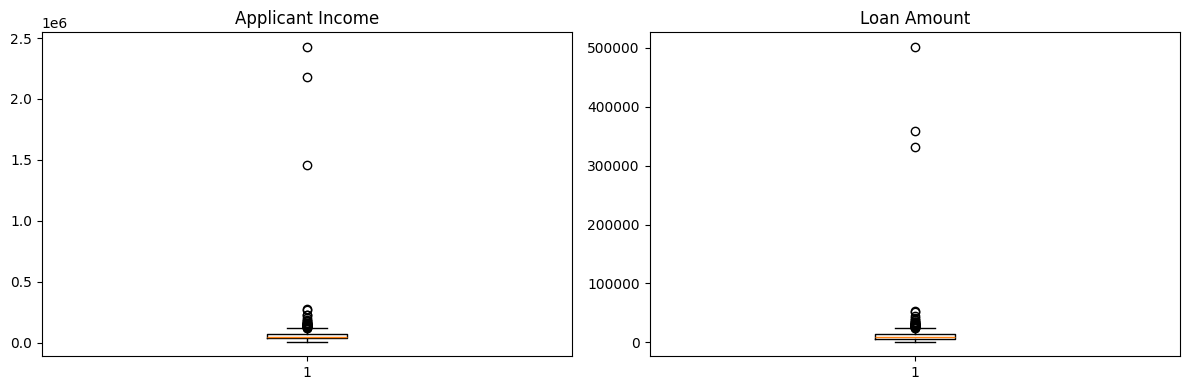

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].boxplot(loans["Applicant_Income"])
axes[0].set_title("Applicant Income")

axes[1].boxplot(loans["Loan_Amount"])
axes[1].set_title("Loan Amount")

plt.tight_layout()
plt.show()

### Observation

A handful of points sit far above the rest of the data (a few applicants with unusually high income or loan requests). Rather than deleting these rows and losing data, we'll **cap** them using the IQR (Interquartile Range) method - a common real-world technique.

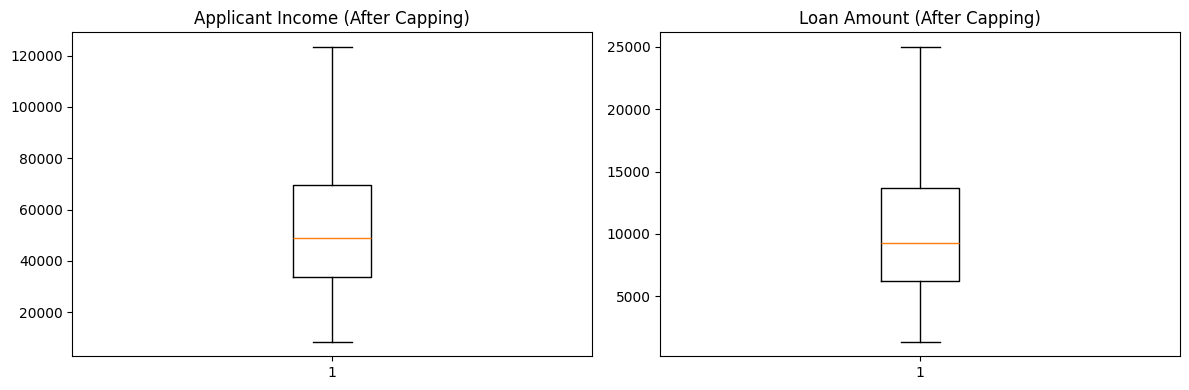

In [16]:
def cap_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df[column] = df[column].clip(lower=lower_bound, upper=upper_bound)
    return df

for col in ["Applicant_Income", "Coapplicant_Income", "Loan_Amount"]:
    loans = cap_outliers_iqr(loans, col)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot(loans["Applicant_Income"])
axes[0].set_title("Applicant Income (After Capping)")
axes[1].boxplot(loans["Loan_Amount"])
axes[1].set_title("Loan Amount (After Capping)")
plt.tight_layout()
plt.show()

### What is `clip()` Doing?

`clip(lower=..., upper=...)` doesn't delete rows. Any value below `lower_bound` is pulled up to `lower_bound`, and any value above `upper_bound` is pulled down to `upper_bound`. We keep every applicant's record, but extreme values can no longer distort training.

### Observation

Our dataset is now clean: consistent text, no missing values, no duplicates, and outliers under control - just like a data scientist would prepare it before a real project.

In [17]:
loans.describe()

,Dependents,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Term_Months,Credit_Score,Years_Employed,Existing_Loans,Loan_Approved
count,1000.0000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,0.9650,54197.656826,9142.69527,10495.243377,270.240000,650.312000,4.973200,0.503000,0.572000
std,1.0143,27482.495741,12249.26908,5836.324478,79.002429,75.828086,5.125604,0.674126,0.495036
min,0.0000,8542.530000,0.00000,1379.910000,120.000000,448.000000,0.000000,0.000000,0.000000
25%,0.0000,33729.485000,0.00000,6196.100000,225.000000,601.000000,1.400000,0.000000,0.000000
50%,1.0000,48786.775000,0.00000,9266.695000,300.000000,651.000000,3.300000,0.000000,1.000000
75%,2.0000,69561.662500,16276.90000,13709.315000,360.000000,700.000000,6.825000,1.000000,1.000000
max,3.0000,123309.928750,40692.25000,24979.137500,360.000000,850.000000,33.800000,2.000000,1.000000


# Part 10 - Encoding Categorical Variables

Just like in Week 3, a Neural Network only understands numbers - every text column must be converted.

We'll use **One-Hot Encoding** for all our categorical columns, since none of them (Gender, Married, Education, Self_Employed, Property_Area) has a natural order.

In [18]:
categorical_features = ["Gender", "Married", "Education", "Self_Employed", "Property_Area"]

loans_encoded = pd.get_dummies(loans, columns=categorical_features, dtype=int)

loans_encoded.head()

,Applicant_ID,Dependents,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Term_Months,Credit_Score,Years_Employed,Existing_Loans,Loan_Approved,...,Gender_Male,Married_No,Married_Yes,Education_Graduate,Education_Not Graduate,Self_Employed_No,Self_Employed_Yes,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
0,LN100487,2.0,37588.18,8795.55,6204.740,180,676.0,9.0,0,1,...,1,1,0,1,0,1,0,0,1,0
1,LN100824,0.0,25573.68,0.00,5855.690,360,609.0,3.6,0,1,...,1,0,1,1,0,1,0,0,1,0
2,LN100735,2.0,90057.91,29303.66,14043.510,180,742.0,3.9,0,1,...,0,1,0,1,0,0,1,0,0,1
3,LN100512,0.0,98440.57,0.00,12115.840,300,606.0,2.0,0,0,...,0,1,0,0,1,0,1,1,0,0
4,LN100203,0.0,11534.51,0.00,9266.695,360,667.0,18.9,0,1,...,1,0,1,0,1,1,0,0,0,1


`pd.get_dummies()` replaces each categorical column with several `0`/`1` columns - one per category. For example, `Property_Area` becomes three columns: `Property_Area_Urban`, `Property_Area_Semiurban`, and `Property_Area_Rural`.

# Part 11 - Features, Target, and Feature Scaling

## Selecting Features and Target

In [19]:
feature_columns = [c for c in loans_encoded.columns if c not in ["Applicant_ID", "Loan_Approved"]]

X = loans_encoded[feature_columns]
y = loans_encoded["Loan_Approved"]

print("Number of features:", X.shape[1])
X.head()

Number of features: 19


,Dependents,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Term_Months,Credit_Score,Years_Employed,Existing_Loans,Gender_Female,Gender_Male,Married_No,Married_Yes,Education_Graduate,Education_Not Graduate,Self_Employed_No,Self_Employed_Yes,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
0,2.0,37588.18,8795.55,6204.740,180,676.0,9.0,0,0,1,1,0,1,0,1,0,0,1,0
1,0.0,25573.68,0.00,5855.690,360,609.0,3.6,0,0,1,0,1,1,0,1,0,0,1,0
2,2.0,90057.91,29303.66,14043.510,180,742.0,3.9,0,1,0,1,0,1,0,0,1,0,0,1
3,0.0,98440.57,0.00,12115.840,300,606.0,2.0,0,1,0,1,0,0,1,0,1,1,0,0
4,0.0,11534.51,0.00,9266.695,360,667.0,18.9,0,0,1,0,1,0,1,1,0,0,0,1


We drop `Applicant_ID` because it is just a unique label with no predictive meaning, and `Loan_Approved` because that is our target.

## Why Does a Neural Network Need Feature Scaling?

In Week 5 Day 2, we learned that Decision Trees **do not** need feature scaling, because a tree only cares about the *order* of values, not their scale.

A Neural Network is different. It computes weighted sums like:

```
z = w1 * Applicant_Income + w2 * Existing_Loans + ...
```

`Applicant_Income` might be in the tens of thousands, while `Existing_Loans` is `0`, `1`, or `2`. Without scaling, the network would be dominated by whichever feature happens to have the largest raw numbers - not necessarily the most important one. Scaling puts every feature on a comparable footing.

In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train_scaled.shape[0])
print("Testing samples:", X_test_scaled.shape[0])

Training samples: 800
Testing samples: 200


### Why `fit_transform()` on Training Data, but only `transform()` on Test Data?

`fit_transform()` **learns** the mean and standard deviation from the training data, then scales it. We then use `transform()` (without `fit`) on the test data, applying the **same** learned scaling.

If we called `fit_transform()` on the test set too, the model would get an unfair sneak-preview of the test data's statistics - a common real-world mistake called **data leakage**.

# Part 12 - Build the Artificial Neural Network

Now we assemble many Perceptron-like neurons into a full network using Keras's `Sequential` API - a simple way to stack layers one after another.

In [21]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.summary()

E0000 00:00:1787464783.942670     474 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 465 (1.82 KB)

 Trainable params: 465 (1.82 KB)

 Non-trainable params: 0 (0.00 B)

### Reading This Architecture, Layer by Layer

- **`Input(shape=(X_train_scaled.shape[1],))`** - tells the network how many features (columns) each applicant record has. This is not a "real" layer, just a doorway in.
- **`Dense(16, activation="relu")`** - our first hidden layer, with 16 neurons. `Dense` means every neuron here connects to every input. ReLU is used because this is a hidden layer (Part 3).
- **`Dense(8, activation="relu")`** - a second hidden layer with 8 neurons, letting the network combine the first layer's patterns into more refined ones.
- **`Dense(1, activation="sigmoid")`** - the output layer. A single neuron, because we need one number: the probability of loan approval. Sigmoid squashes that number into a probability between 0 and 1 (Part 3) - the same idea as Logistic Regression in Week 5!

There is no fixed rule for how many hidden layers or neurons to use - this is a starting point we could later experiment with, similar to how we experimented with `max_depth` for Decision Trees.

## Compile the Model

Before training, we tell Keras **how** to learn.

In [22]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

### What Do These Settings Mean?

- **`optimizer="adam"`** - the algorithm that adjusts weights after every batch of data (an advanced, faster version of the simple "nudge the weights" rule we hand-coded in Part 6).
- **`loss="binary_crossentropy"`** - the function that measures how wrong a prediction is. It is the standard choice for binary classification (0/1 outputs), just like accuracy and confusion matrices were our evaluation tools for Logistic Regression.
- **`metrics=["accuracy"]`** - what we want reported after every epoch, in addition to the loss.

# Part 13 - Train the Model

`.fit()` is where the actual learning happens - forward pass, error calculation, and weight adjustment, repeated automatically.

In [23]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=40,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)

print("Training complete.")

Training complete.


### Understanding the Parameters

- **`epochs=40`** - the network sees the entire training set 40 times.
- **`batch_size=16`** - instead of updating weights after every single row, the network looks at 16 applicants at a time before adjusting. This makes training faster and more stable.
- **`validation_split=0.2`** - Keras automatically holds back 20% of the *training* data (separate from our test set) to check for overfitting after every epoch, similar in spirit to why we keep a test set at all.
- **`verbose=0`** - keeps the notebook output tidy; we'll visualize the same information as a chart next instead.

## Visualize Training Progress

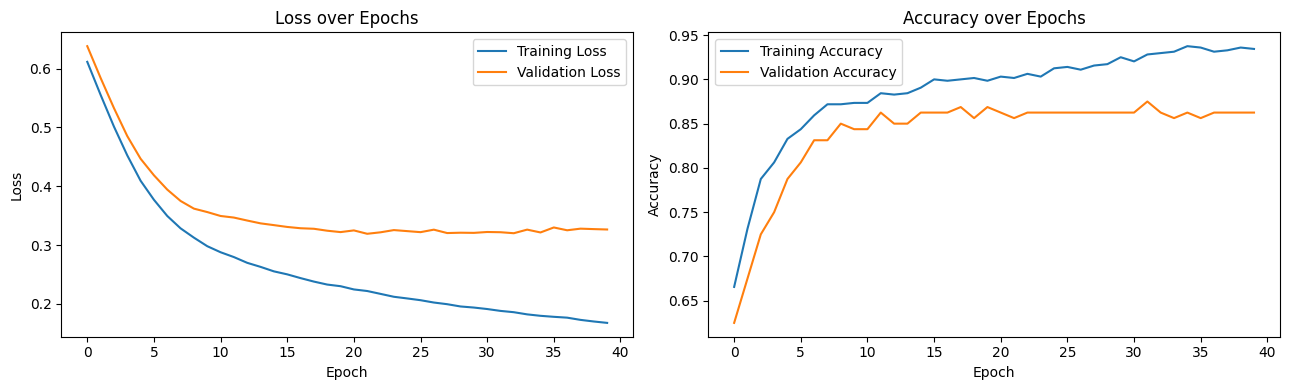

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["loss"], label="Training Loss")
axes[0].plot(history.history["val_loss"], label="Validation Loss")
axes[0].set_title("Loss over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Training Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("Accuracy over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

### Reading These Charts

- If **training loss keeps falling** but **validation loss starts rising**, the model is **overfitting** - memorising the training data rather than learning general patterns (the same concept we met with deep Decision Trees in Week 5 Day 2).
- If both curves flatten out together at a low loss / high accuracy, the model is learning well and generalising.

# Part 14 - Evaluate the Model

Now we check performance on the **test set** - data the model has never seen in any form during training.

In [25]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))

Test Loss: 0.3256
Test Accuracy: 0.84


In [26]:
probabilities = model.predict(X_test_scaled, verbose=0)
predictions = (probabilities > 0.5).astype(int).flatten()

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": predictions,
    "Probability": probabilities.flatten().round(3)
})

comparison.head(10)

,Actual,Predicted,Probability
0,0,0,0.139
1,0,1,0.561
2,1,1,1.000
3,1,1,0.998
4,0,0,0.043
5,0,0,0.077
6,1,1,0.976
7,0,0,0.008
8,0,1,0.860
9,1,1,0.678


### Why `> 0.5`?

The output layer's Sigmoid gives us a *probability*, not a class. `0.5` is the default decision threshold: anything at or above `0.5` becomes `1` (Approved), anything below becomes `0` (Rejected) - the exact same idea we used for Logistic Regression in Week 5 Day 1.

In [27]:
cm = confusion_matrix(y_test, predictions)
cm

array([[ 65,  21],
       [ 11, 103]])

In [28]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.86      0.76      0.80        86
           1       0.83      0.90      0.87       114

    accuracy                           0.84       200
   macro avg       0.84      0.83      0.83       200
weighted avg       0.84      0.84      0.84       200



### Interpreting the Confusion Matrix

|  | Predicted: Rejected | Predicted: Approved |
|---|---|---|
| **Actual: Rejected** | True Negative | False Positive |
| **Actual: Approved** | False Negative | True Positive |

In a real bank, a **False Positive** (approving a loan that should have been rejected) is usually far more costly than a **False Negative** (rejecting a loan that should have been approved). This is worth keeping in mind - accuracy alone never tells the whole story.

# Part 15 - Predict a Brand-New Applicant

Let's simulate a loan officer entering a new applicant's details and getting an instant prediction.

In [29]:
new_applicant = pd.DataFrame([{
    "Dependents": 1,
    "Applicant_Income": 85000,
    "Coapplicant_Income": 20000,
    "Loan_Amount": 15000,
    "Loan_Term_Months": 240,
    "Credit_Score": 710,
    "Years_Employed": 6.5,
    "Existing_Loans": 0,
    "Gender_Female": 0, "Gender_Male": 1,
    "Married_No": 0, "Married_Yes": 1,
    "Education_Graduate": 1, "Education_Not Graduate": 0,
    "Self_Employed_No": 1, "Self_Employed_Yes": 0,
    "Property_Area_Rural": 0, "Property_Area_Semiurban": 1, "Property_Area_Urban": 0,
}])

# Make sure the column order matches what the model was trained on
new_applicant = new_applicant[feature_columns]

new_applicant_scaled = scaler.transform(new_applicant)
probability = model.predict(new_applicant_scaled, verbose=0)[0][0]
decision = "Approved" if probability > 0.5 else "Rejected"

print(f"Predicted probability of approval: {probability:.3f}")
print(f"Decision: {decision}")

Predicted probability of approval: 0.988
Decision: Approved


Notice that we reused the **same** `scaler` and the **same** `feature_columns` order from training. A model can only make sense of new data if it is prepared in exactly the same way as the training data.

# Mini Practical Activity

Using the cleaned `loans_encoded` dataset:

1. Change the network to have 3 hidden layers instead of 2.
2. Retrain for 40 epochs and compare the test accuracy to our original model.
3. Try `batch_size=32` instead of `16` - does training look smoother or noisier?
4. Change the decision threshold from `0.5` to `0.6` and see how the confusion matrix changes.

### Exercise 1

Add a third hidden layer with 4 neurons to the model, right before the output layer. Retrain and report the new test accuracy.

### Exercise 2

Try replacing `activation="relu"` in the hidden layers with `activation="tanh"`. Does accuracy improve, stay the same, or get worse?

### Exercise 3

Using `model.predict()`, find one applicant in the test set who was predicted **Rejected** with high confidence (probability below 0.2). Look at their raw features - can you explain, in plain language, why the model likely rejected them?

# Lesson Summary

Today, you learned how to:

- Explain the journey from a biological neuron to an artificial one.
- Build and train a Perceptron completely from scratch with NumPy.
- Identify Step, Sigmoid, and ReLU activation functions and when each is used.
- Distinguish ANN, CNN, and RNN/Transformer architectures.
- Install and verify TensorFlow/Keras.
- Clean a large, messy, real-world-style dataset (missing values, inconsistent text, duplicates, outliers).
- Encode categorical features and scale numerical features for a Neural Network.
- Build, compile, and train a Keras `Sequential` ANN.
- Evaluate the model with accuracy, a confusion matrix, and a classification report.
- Use a trained model to predict a brand-new applicant's outcome.

# Functions and Concepts Learned Today

| Item | Purpose |
|---|---|
| Neuron | The basic computing unit: inputs → weighted sum + bias → activation → output |
| Perceptron | The simplest single-neuron model, using a Step activation function |
| Weight | A learned number controlling how much influence an input has |
| Bias | A learned constant that shifts the weighted sum |
| Activation Function | Decides how a neuron "fires" (Step, Sigmoid, ReLU) |
| ANN | Artificial Neural Network - many neurons arranged in fully-connected layers |
| CNN | Convolutional Neural Network - specialised for image data |
| RNN / Transformer | Neural networks specialised for sequences (text, speech) |
| `str.strip()` / `str.title()` | Cleans inconsistent text formatting |
| `fillna()` | Fills missing values (median for numeric, mode for categorical here) |
| `drop_duplicates()` | Removes repeated rows |
| IQR capping / `clip()` | Limits extreme outlier values without deleting rows |
| `pd.get_dummies()` | One-Hot Encoding for categorical columns |
| `StandardScaler` | Scales numeric features to comparable ranges - required for Neural Networks |
| `train_test_split()` | Splits data into training and testing sets |
| `Sequential` | Keras API for stacking layers in order |
| `Dense` | A fully-connected neural network layer |
| `Input(shape=...)` | Defines how many features the network expects |
| `model.compile()` | Configures the optimizer, loss function, and metrics |
| `optimizer="adam"` | Algorithm that updates weights during training |
| `loss="binary_crossentropy"` | Error measure for binary classification |
| `model.fit()` | Trains the network |
| `epochs` | Number of full passes over the training data |
| `batch_size` | Number of samples processed before each weight update |
| `validation_split` | Portion of training data held back to monitor overfitting live |
| `model.evaluate()` | Reports loss and accuracy on unseen data |
| `model.predict()` | Produces predicted probabilities |
| `confusion_matrix()` / `classification_report()` | Detailed classification evaluation, as used since Week 5 |

# Key Takeaways

✅ Every Neural Network is built from the same basic unit: the neuron.

✅ A neuron computes a weighted sum, adds a bias, then applies an activation function.

✅ The Perceptron is the simplest neuron, but a single one can't solve every problem.

✅ Stacking neurons into layers (an ANN) lets the network learn non-linear patterns.

✅ ReLU is the default for hidden layers; Sigmoid is standard for binary-classification output layers.

✅ CNNs specialise in images; RNNs/Transformers specialise in sequences; ANNs work well on tabular data like today's loan records.

✅ Neural Networks, unlike Decision Trees, require feature scaling.

✅ Cleaning a large, messy dataset (missing values, inconsistent text, duplicates, outliers) is a mandatory first step before training - not an optional one.

✅ Training/validation loss curves reveal overfitting long before it shows up in a single accuracy number.

# Assignment

Submit a Jupyter Notebook containing:

1. A short description of the dataset used (features and target).
2. Full data cleaning steps (missing values, inconsistent text, duplicates, at least one outlier-handling technique).
3. Encoding of all categorical features.
4. Feature scaling with a written explanation of why it's needed for a Neural Network.
5. A train/test split.
6. A Keras `Sequential` model with at least two hidden layers.
7. Model compilation with a stated optimizer and loss function.
8. Training with at least 30 epochs, and a plotted loss/accuracy chart.
9. Test accuracy, a confusion matrix, and a classification report.
10. A short paragraph explaining whether your model overfit, underfit, or generalised well, using the training/validation curves as evidence.
11. One prediction made on a brand-new, hand-crafted applicant record.

# Final Reflection

Answer these questions:

1. What is a neuron, in your own words?
2. What do weights and bias each control?
3. Why do we need an activation function at all?
4. What is the key difference between the Step and Sigmoid functions?
5. Why is ReLU preferred in hidden layers over Sigmoid?
6. What kind of problem is a single Perceptron unable to solve?
7. What distinguishes an ANN from a CNN from an RNN?
8. Why does a Neural Network need feature scaling but a Decision Tree does not?
9. What does an epoch represent during training?
10. What is the purpose of `validation_split`?
11. How do you read an overfitting pattern from a loss curve?
12. Why must you use the same `scaler` object on both training and test data?
13. What does the Sigmoid output of the final layer actually represent?
14. Why did we cap outliers instead of deleting those rows?
15. How is training a Keras model similar to, and different from, the NumPy Perceptron we built by hand?

# Preview: Week 6 - Day 2

Next lesson, we go deeper into building Neural Networks with Keras:

- Experimenting with the number of layers and neurons.
- Understanding epochs and batch size more formally.
- Introducing dropout and other techniques to reduce overfitting.
- Comparing our ANN's performance against Week 5's Logistic Regression and Decision Tree on a related classification problem.

We're building toward Week 7, where we'll extend these same neuron principles into **Convolutional Neural Networks (CNNs)** for image data.